# ITCS 6169/8169 — Computer Vision
## Assignment 2: BYOL-style CNN (from scratch, self-supervised) — comparison with SigLIP

Same encoder, split, 64px cache, linear-probe protocol and fine-tuning recipe as the SigLIP notebook, so the only thing that changes is the **SSL objective**.

**BYOL in one paragraph.** No negatives. An *online* network (encoder → projector → **predictor**) is trained to predict the output of a *target* network (encoder → projector) that sees the other augmented view. The target is not trained by gradients: it is an exponential moving average (EMA) of the online weights. The asymmetry (predictor + EMA target + stop-gradient) is what prevents the trivial "output a constant" solution, so we monitor a **collapse indicator** (`z_std`) during training.

**Plan (target ≲ 1.5 h)**
1. Controls and a quick collapse check.
2. One-knob ablations (50 SSL epochs, linear probe): EMA momentum `tau`, LR, batch size (the batch-size independence of BYOL is the interesting contrast with SigLIP). Same protocol and a comparable number of runs as the SigLIP notebook, so the tuning effort is roughly matched.
3. Combine what clearly helped; final 200-epoch runs, 2 seeds → fine-tune → validation → test once.
4. Side-by-side with the SigLIP results saved in `checkpoints/`.

Augmentation, LR, weight decay and batch size start from whatever the SigLIP notebook selected (`checkpoints/siglip_final_cfg.json`), so the comparison is not confounded by augmentation. Set `SMOKE_TEST = True` first.

> **128px finals-only mode.** This is the same notebook as the 64px version with `IMG_SIZE = 128`. All ablation / search cells are skipped; the configuration chosen at 64px is loaded from `checkpoints/` and trained at the higher resolution. Results and checkpoints get a `128px_` prefix, so nothing from the 64px runs is overwritten or reused. **Prerequisite:** the 64px notebook must have been run in the same project folder. Restart the kernel and check the GPU is free before starting.

In [1]:
# Core imports
from pathlib import Path
import random, time, copy, math, json, gc, threading, queue

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from PIL import Image

try:
    import torch_directml  # to allow for AMD gpu usage
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"DirectML available: {HAS_DML}")

PyTorch version: 2.4.1+cpu
CUDA available: False
DirectML available: True


In [2]:
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment2
Training data: data\train
Testing data: data\test


In [3]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_device():
    """CUDA if available, else DirectML (AMD GPU on Windows), else CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if HAS_DML:
        return torch_directml.device()
    return torch.device("cpu")

set_random_seed(SEED)
device = get_device()
print('Device:', device)

Device: privateuseone:0


## Config

In [4]:
SMOKE_TEST = False   # True -> tiny runs, just to check the notebook runs end-to-end
IMG_SIZE = 128           # 64 = the tuned setting; any other size runs in FINALS_ONLY mode
PREFIX = ('smoke_' if SMOKE_TEST else '') + ('' if IMG_SIZE == 64 else f'{IMG_SIZE}px_')   # keeps smoke / other-resolution files separate
FINALS_ONLY = IMG_SIZE != 64   # skip all ablations; reuse the config selected by the 64px notebook
HIRES_SSL_BS = 64        # FINALS_ONLY: SSL batch size (a 128px batch of 128 image pairs may not fit in GPU memory)
HIRES_SSL_EPOCHS = 100   # FINALS_ONLY: SSL epochs (the 64px probe curves plateaued around epoch 100-120)

# Data
BATCH_SIZE = 32          # fine-tuning batch size
VAL_FRACTION = 0.20

# Fine-tuning recipe (identical to the SigLIP notebook / A1)
SUP_LR = 5e-4
SUP_WD = 0.05
MIXUP_ALPHA = 0.4
CUTMIX_ALPHA = 1.0
CUTMIX_PROB = 0.5
FT_EPOCHS = 100

FEAT_DIM = 256

# ---- Start from the SigLIP notebook's chosen augmentation / optimiser settings ----
_shared = dict(bs=128, lr=1e-3, wd=0.05, crop_min=0.3, jitter=0.4, gray_p=0.2, proj_hidden=512, proj_dim=128)
_siglip_cfg_file = PROJECT_ROOT / 'checkpoints' / f"{'smoke_' if SMOKE_TEST else ''}siglip_final_cfg.json"   # the 64px selection
if _siglip_cfg_file.exists():
    _sg = json.loads(_siglip_cfg_file.read_text())
    _shared.update({k: _sg[k] for k in _shared})
    print('Loaded shared settings from', _siglip_cfg_file)
else:
    print('No siglip_final_cfg.json found -> using the default shared settings')

# ---- BYOL-specific knobs ----
BASE_CFG = dict(**_shared,
    tau=0.99,            # EMA momentum at the start; increases to 1.0 along a cosine schedule
    pred_hidden=512,     # predictor hidden width
)

if FINALS_ONLY:
    BASE_CFG['bs'] = HIRES_SSL_BS      # the speed / collapse checks must use the same (smaller) batch as the real runs

GRID = {                 # one knob at a time (values equal to the base are skipped)
    'tau': [0.9, 0.996],                         # EMA momentum: the BYOL-specific knob
    'lr':  [BASE_CFG['lr'] / 2, BASE_CFG['lr'] * 2],
    'bs':  [BASE_CFG['bs'] // 2, BASE_CFG['bs'] * 2],   # BYOL should not need in-batch negatives
}
RUN_NOISE_CHECK = True   # also run the base config with seed 1 to measure run-to-run noise (as in the SigLIP notebook)

# ---- Budget ----
ABL_EPOCHS = 50
ABL_PROBE_EVERY = 10
MIN_GAIN = 0.02
MANUAL_OVERRIDE = {}
FORCE_RERUN = False
COLLAPSE_STD = 0.02      # z_std below this => the representation has (nearly) collapsed
EMA_EVERY = 4            # update the target every k steps with tau**k: same averaging timescale, 1/k of the tiny-kernel
                         # launches (many small ops are slow on DirectML). Set to 1 for the textbook per-step update.

FINAL_SSL_EPOCHS = 200
FINAL_PROBE_EVERY = 10
FINAL_SEEDS = (0, 1)

if SMOKE_TEST:
    ABL_EPOCHS = FINAL_SSL_EPOCHS = FT_EPOCHS = 2
    ABL_PROBE_EVERY = FINAL_PROBE_EVERY = 1
    GRID = dict(list(GRID.items())[:2])
    FINAL_SEEDS = (0,)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
print('BASE_CFG:', BASE_CFG)

Loaded shared settings from checkpoints\siglip_final_cfg.json
BASE_CFG: {'bs': 64, 'lr': 0.0005, 'wd': 0.05, 'crop_min': 0.3, 'jitter': 0.4, 'gray_p': 0.2, 'proj_hidden': 512, 'proj_dim': 128, 'tau': 0.99, 'pred_hidden': 512}


## Data

In [5]:
# Mixup / CutMix helpers (from A1)
def mixup_data(x, y, alpha=0.2):
    '''Returns mixed inputs, pairs of targets, and lambda.'''
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)

    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def cutmix_data(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_ratio), int(W * cut_ratio)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)

    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (H * W))   # correct lam for the clipped box
    return x, y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def random_grayscale_rgb(img):
    # Augment only on training; validation/test should stay clean.
    if random.random() < 0.5:
        gray = img.convert("L")
        return gray.convert("RGB")
    return img

class Prefetch:
    """Runs a DataLoader in a background thread so augmentation overlaps with GPU compute."""
    def __init__(self, loader, depth=3):
        self.loader, self.depth = loader, depth

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        q = queue.Queue(maxsize=self.depth)
        done = object()
        def work():
            try:
                for item in self.loader:
                    q.put(item)
            except Exception as e:          # hand errors to the main thread instead of hanging it
                q.put(e)
            q.put(done)
        threading.Thread(target=work, daemon=True).start()
        while True:
            item = q.get()
            if item is done:
                return
            if isinstance(item, Exception):
                raise item
            yield item

In [6]:
# Fine-tuning augmentation (from A1) and clean eval preprocessing
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.Lambda(random_grayscale_rgb),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def build_ssl_aug(crop_min=0.3, jitter=0.4, gray_p=0.2):
    """SSL view augmentation; the three arguments are ablation knobs."""
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(crop_min, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomApply([transforms.ColorJitter(jitter, jitter, jitter, jitter / 4)], p=0.8),
        transforms.RandomGrayscale(p=gray_p),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

ssl_aug = build_ssl_aug(BASE_CFG['crop_min'], BASE_CFG['jitter'], BASE_CFG['gray_p'])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

class TwoView(torch.utils.data.Dataset):
    """Two independently augmented views of the same image (the label is returned but never used by SSL)."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        return self.transform(image), self.transform(image), label

In [7]:
base_train_dataset = datasets.ImageFolder(TRAIN_ROOT)
class_names = base_train_dataset.classes
num_classes = len(class_names)

# decode + resize once; the split below uses a seeded generator so it is identical in every run
cached_train = [(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), y) for img, y in base_train_dataset]

val_size = int(round(len(base_train_dataset) * VAL_FRACTION))
train_size = len(base_train_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(cached_train, [train_size, val_size], generator=generator)

train_dataset = TransformSubset(train_subset, train_transform)
val_dataset = TransformSubset(val_subset, eval_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=eval_transform)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

def make_ssl_loader(bs=None, aug=None):
    """Two-view loader over the TRAIN split only (never val/test). drop_last keeps batches full."""
    return Prefetch(DataLoader(TwoView(train_subset, aug or ssl_aug), batch_size=bs or BASE_CFG['bs'],
                               shuffle=True, drop_last=True, num_workers=0, pin_memory=pin))

print(f'Classes ({num_classes}): {class_names}')
print(f'Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')

Classes (16): ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Train: 1920 | Validation: 480 | Test: 400


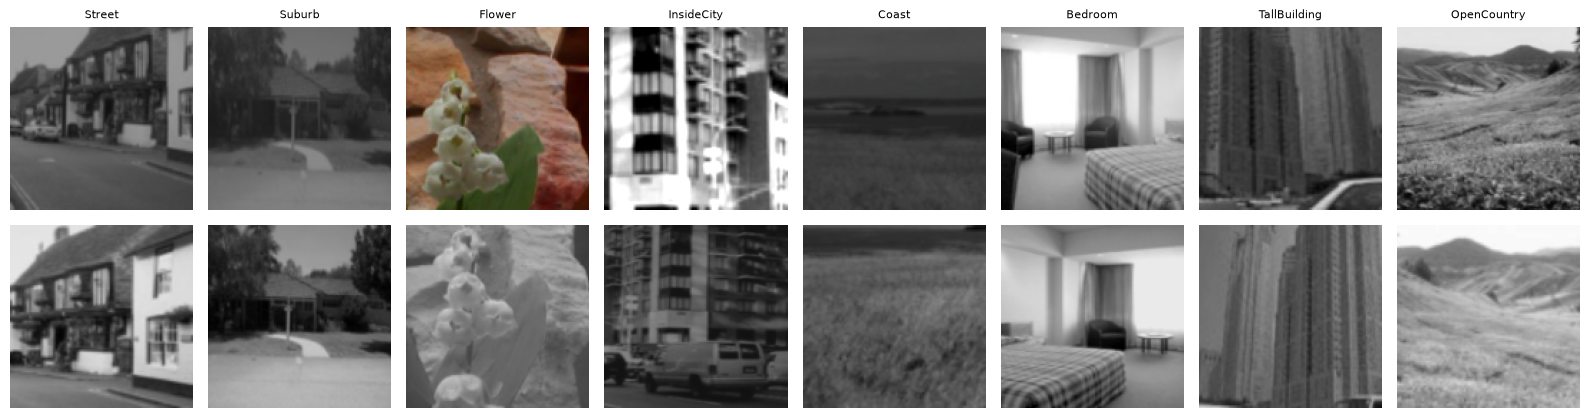

In [8]:
# Sanity check: pairs of SSL views (each column = one image; rows = its two views).
def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

v1, v2, y = next(iter(make_ssl_loader(bs=8)))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    axes[0, i].imshow(denorm(v1[i])); axes[0, i].set_title(class_names[y[i].item()], fontsize=8)
    axes[1, i].imshow(denorm(v2[i]))
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout()
plt.show()

## Models and loss
`SSLNet` (encoder + pool + **projector**) is the same network as in the SigLIP notebook, so checkpoints, the probe and fine-tuning work unchanged. BYOL adds a **predictor** on the online side and a **target** copy updated by EMA. Loss = `2 − 2·cos(predictor(online(view A)), stopgrad(target(view B)))`, symmetrised over the two views.

In [9]:
def conv_bn_relu(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )

class TNet(nn.Module):
    def __init__(self, num_classes=16, widths=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = widths
        self.features = nn.Sequential(
            conv_bn_relu(3, c1), conv_bn_relu(c1, c1), nn.MaxPool2d(2),
            conv_bn_relu(c1, c2), conv_bn_relu(c2, c2), nn.MaxPool2d(2),
            conv_bn_relu(c2, c3), conv_bn_relu(c3, c3), nn.MaxPool2d(2),
            conv_bn_relu(c3, c4), conv_bn_relu(c4, c4),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c4, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class SSLNet(nn.Module):
    """Encoder (TNet conv stack) + global pool + projection head."""
    def __init__(self, feat_dim=FEAT_DIM, hidden=BASE_CFG['proj_hidden'], proj_dim=BASE_CFG['proj_dim']):
        super().__init__()
        self.features = TNet(num_classes=num_classes).features
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())
        self.head = nn.Sequential(
            nn.Linear(feat_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, proj_dim),
        )

    def embed(self, x):          # representation used for probing / fine-tuning
        return self.pool(self.features(x))

    def forward(self, x):        # projection used by the SSL loss
        return self.head(self.embed(x))


print(f'TNet trainable parameters: {sum(p.numel() for p in TNet(num_classes=num_classes).parameters()):,}')
print(f'SSLNet trainable parameters: {sum(p.numel() for p in SSLNet().parameters()):,}')

TNet trainable parameters: 1,177,328
SSLNet trainable parameters: 1,371,488


## Training utilities

In [10]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    running_loss = 0.0
    criterion = nn.CrossEntropyLoss()
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, scheduler=None, epochs=20, device=device,
                mixup_alpha=0.0, cutmix_alpha=1.0, cutmix_prob=0.0, print_every=1):
    criterion = nn.CrossEntropyLoss()
    model = model.to(device)
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_seen = 0
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            # Pick at most one mixing method per batch
            use_cutmix = cutmix_prob > 0 and np.random.rand() < cutmix_prob
            use_mixup = (not use_cutmix) and mixup_alpha > 0
            if use_cutmix:
                images, labels_a, labels_b, lam = cutmix_data(images, labels, alpha=cutmix_alpha)
            elif use_mixup:
                images, labels_a, labels_b, lam = mixup_data(images, labels, alpha=mixup_alpha)

            logits = model(images)
            if use_cutmix or use_mixup:
                loss = mixup_criterion(criterion, logits, labels_a, labels_b, lam)
            else:
                loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            total_seen += labels.size(0)

        train_loss = total_loss / total_seen
        val_loss, val_acc = evaluate(model, val_loader, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if scheduler is not None:
            scheduler.step()
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        if epoch % print_every == 0 or epoch == epochs:
            print(f'Epoch {epoch:03d}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
                  f'val acc {val_acc:.4f} | {time.time() - start:.1f}s')

    last_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f'Best validation accuracy: {best_val_acc:.4f}')
    return model, history, best_state, last_state


# ---- Linear probe: how good are the frozen features? ----
@torch.no_grad()
def embed_dataset(net, loader):
    net.eval()
    feats, ys = [], []
    for x, y in loader:
        feats.append(net.embed(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(feats), torch.cat(ys)

def linear_probe(net, steps=300, lr=1e-2, wd=1e-4):
    """Linear layer on FROZEN encoder features (train split, no augmentation) -> validation accuracy."""
    train_clean = DataLoader(TransformSubset(train_subset, eval_transform), batch_size=128, shuffle=False)
    ftr, ytr = embed_dataset(net, train_clean)
    fva, yva = embed_dataset(net, val_loader)
    mu, sd = ftr.mean(0), ftr.std(0) + 1e-6
    ftr, fva = (ftr - mu) / sd, (fva - mu) / sd

    clf = nn.Linear(ftr.shape[1], num_classes)
    opt = optim.AdamW(clf.parameters(), lr=lr, weight_decay=wd)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(clf(ftr), ytr).backward()
        opt.step()
    with torch.no_grad():
        return (clf(fva).argmax(1) == yva).float().mean().item()

In [11]:
# ---- Checkpoint helpers ----
CKPT_DIR = PROJECT_ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)

def slug(name):
    """'SigLIP CNN final s0' -> 'siglip_cnn_final_s0'"""
    return ''.join(c.lower() if c.isalnum() else '_' for c in name).strip('_')

def cpu_state(sd):
    """Detached CPU copy of a state dict (safe to keep around and to save)."""
    return {k: v.detach().cpu().clone() for k, v in sd.items()}

def save_ckpt(name, stage, best_state, last_state, **extra):
    """Write checkpoints/<slug>_<stage>.pt (temp file first, so a crash can't corrupt the old one)."""
    path = CKPT_DIR / f'{slug(name)}_{stage}.pt'
    tmp = path.with_suffix('.tmp')
    torch.save({'best_state': best_state, 'last_state': last_state, **extra}, tmp)
    tmp.replace(path)
    return path

def load_ckpt(name, stage, which='best'):
    ck = torch.load(CKPT_DIR / f'{slug(name)}_{stage}.pt', map_location='cpu')
    return ck[f'{which}_state'], ck          # which = 'best' or 'last'

def load_pretrained(name, which='best'):
    """Rebuild a pretrained SSLNet (encoder + projection head) from a checkpoint."""
    sd, ck = load_ckpt(name, 'pretrain', which)
    net = SSLNet(**ck['hparams'].get('net_kwargs', {}))
    net.load_state_dict(sd)
    return net.to(device)

def load_finetuned(name, which='best'):
    """Rebuild a fine-tuned TNet classifier from a checkpoint."""
    sd, _ = load_ckpt(name, 'finetune', which)
    model = TNet(num_classes=num_classes)
    model.load_state_dict(sd)
    return model.to(device)

In [12]:
def byol_loss(p, z):
    """2 - 2*cos(p, z) with stop-gradient on the target side."""
    p = F.normalize(p, dim=1)
    z = F.normalize(z.detach(), dim=1)
    return (2 - 2 * (p * z).sum(dim=1)).mean()

@torch.no_grad()
def ema_update(target, online, tau):
    """target <- tau*target + (1-tau)*online. Parameters only: the target always runs in train mode, so its BN
    running statistics are never used. mul_/add_(alpha) avoids a temporary (and lerp falls back to CPU on DirectML)."""
    for pt, po in zip(target.parameters(), online.parameters()):
        pt.mul_(tau).add_(po, alpha=1.0 - tau)

def byol_pretrain(cfg, epochs, seed=SEED, probe_every=10, name='', save=False, print_every=10):
    """BYOL pretraining. Labels are never used. Returns (online SSLNet, log).
    log['z_std'] is the collapse indicator: mean per-dimension std of the L2-normalised online projections
    on the last batch of each epoch (healthy ~ 1/sqrt(proj_dim); ~0 means collapse)."""
    set_random_seed(seed)
    net = SSLNet(hidden=cfg['proj_hidden'], proj_dim=cfg['proj_dim'])
    predictor = nn.Sequential(nn.Linear(cfg['proj_dim'], cfg['pred_hidden']), nn.BatchNorm1d(cfg['pred_hidden']),
                              nn.ReLU(inplace=True), nn.Linear(cfg['pred_hidden'], cfg['proj_dim']))
    target = copy.deepcopy(net)                          # build everything on CPU, then move
    for p in target.parameters():
        p.requires_grad_(False)
    net, predictor, target = net.to(device), predictor.to(device), target.to(device)

    loader = make_ssl_loader(cfg['bs'], build_ssl_aug(cfg['crop_min'], cfg['jitter'], cfg['gray_p']))
    opt = optim.AdamW(list(net.parameters()) + list(predictor.parameters()), lr=cfg['lr'], weight_decay=cfg['wd'])
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    total_steps, step = epochs * len(loader), 0

    log = {'loss': [], 'z_std': [], 'probe_epoch': [], 'probe_acc': []}
    best_probe, best_epoch, best_state = -1.0, 0, None
    hparams = dict(method='BYOL', cfg=cfg, epochs=epochs, seed=seed,
                   net_kwargs=dict(hidden=cfg['proj_hidden'], proj_dim=cfg['proj_dim']))
    start = time.time()
    for ep in range(1, epochs + 1):
        net.train(); predictor.train(); target.train()
        tot, n = 0.0, 0
        for v1, v2, _ in loader:                          # label ignored
            x = torch.cat([v1, v2]).to(device)
            out = net(x)                                  # online projections of both views
            p1, p2 = predictor(out).chunk(2)
            with torch.no_grad():
                t1, t2 = target(x).chunk(2)
            loss = (byol_loss(p1, t2) + byol_loss(p2, t1)) / 2     # each view predicts the OTHER view's target
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tau = 1.0 - (1.0 - cfg['tau']) * (math.cos(math.pi * step / total_steps) + 1.0) / 2.0
            if (step + 1) % EMA_EVERY == 0:
                ema_update(target, net, tau ** EMA_EVERY)       # k steps at momentum tau ~= 1 step at tau**k
            step += 1
            tot += loss.item(); n += 1
        sched.step()
        avg = tot / n
        z_std = F.normalize(out.detach(), dim=1).std(0).mean().item()
        log['loss'].append(avg); log['z_std'].append(z_std)

        line = f'[{name}] ep {ep:03d}/{epochs} | byol loss {avg:.4f} | z_std {z_std:.3f}'
        do_probe = (ep % probe_every == 0) or (ep == epochs)
        if do_probe:
            acc = linear_probe(net)                       # probe the ONLINE encoder
            log['probe_epoch'].append(ep); log['probe_acc'].append(acc)
            if acc > best_probe:
                best_probe, best_epoch, best_state = acc, ep, cpu_state(net.state_dict())
            line += f' | probe val acc {acc:.4f} (best {best_probe:.4f} @ {best_epoch}) | tau {tau:.4f}'
            if z_std < COLLAPSE_STD:
                line += '  <-- COLLAPSED?'
            if save and name:
                save_ckpt(name, 'pretrain', best_state, cpu_state(net.state_dict()),
                          predictor_state=cpu_state(predictor.state_dict()), target_state=cpu_state(target.state_dict()),
                          log=log, hparams=hparams, best_probe_acc=best_probe, best_probe_epoch=best_epoch, last_epoch=ep)
        line += f' | {time.time() - start:.0f}s'
        if do_probe or ep % print_every == 0:
            print(line)

    log['best_probe_acc'], log['best_probe_epoch'] = best_probe, best_epoch
    log['seconds'] = time.time() - start
    return net, log

In [13]:
def finetune(net=None, epochs=None, lr=None, enc_lr_mult=1.0, mix=True, print_every=10):
    """net=None -> fresh TNet; otherwise start from net's encoder.
    enc_lr_mult scales the encoder LR relative to the classifier; mix=False turns off mixup/CutMix."""
    epochs, lr = epochs or FT_EPOCHS, lr or SUP_LR
    model = TNet(num_classes=num_classes)
    if net is not None:
        # transfer through CPU clones: loading a DirectML state dict directly leaves requires_grad=False
        model.features.load_state_dict({k: v.detach().cpu().clone() for k, v in net.features.state_dict().items()})
    model = model.to(device)
    assert all(p.requires_grad for p in model.parameters()), 'some parameters are frozen'
    optimizer = optim.AdamW([{'params': model.features.parameters(), 'lr': lr * enc_lr_mult},
                             {'params': model.classifier.parameters(), 'lr': lr}], weight_decay=SUP_WD)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return train_model(model, train_loader, val_loader, optimizer, scheduler=scheduler, epochs=epochs,
                       device=device, mixup_alpha=MIXUP_ALPHA if mix else 0.0, cutmix_alpha=CUTMIX_ALPHA,
                       cutmix_prob=CUTMIX_PROB if mix else 0.0, print_every=print_every)

In [14]:
# Bookkeeping for the final models
results = {}      # name -> dict of validation numbers
models = {}       # name -> trained model (best-val weights), for the test-set evaluation at the end
probe_logs = {}   # name -> SSL pretraining log

def record(name, history, model, probe_acc=None, note=''):
    results[name] = {'val_best': max(history['val_acc']), 'val_last': history['val_acc'][-1],
                     'probe_val': probe_acc, 'note': note}
    models[name] = model
    print(f"Logged '{name}': best val {results[name]['val_best']:.4f}, last val {results[name]['val_last']:.4f}")

## Step 0: Controls
A **speed check** (how much of a BYOL step is the EMA update), the random-init encoder floor, and a short BYOL run (10 epochs) to confirm it is **not collapsing**: `z_std` should stay well above `COLLAPSE_STD`. Don't expect the probe to rise much in this check — the LR and EMA schedules are compressed into 10 epochs (the target is frozen by the end), so the real test is the 50-epoch base run.

In [15]:
# --- speed check: how much of a BYOL step is the EMA update? ---
set_random_seed(SEED)
_net = SSLNet(hidden=BASE_CFG['proj_hidden'], proj_dim=BASE_CFG['proj_dim'])
_pred = nn.Sequential(nn.Linear(BASE_CFG['proj_dim'], BASE_CFG['pred_hidden']), nn.BatchNorm1d(BASE_CFG['pred_hidden']),
                      nn.ReLU(inplace=True), nn.Linear(BASE_CFG['pred_hidden'], BASE_CFG['proj_dim']))
_tgt = copy.deepcopy(_net)
for _p in _tgt.parameters():
    _p.requires_grad_(False)
_net, _pred, _tgt = _net.to(device), _pred.to(device), _tgt.to(device)
_opt = optim.AdamW(list(_net.parameters()) + list(_pred.parameters()), lr=1e-3)
_x = torch.randn(2 * BASE_CFG['bs'], 3, IMG_SIZE, IMG_SIZE).to(device)

def _timed(do_ema):
    t0 = time.time()
    p1, p2 = _pred(_net(_x)).chunk(2)
    with torch.no_grad():
        t1, t2 = _tgt(_x).chunk(2)
    loss = (byol_loss(p1, t2) + byol_loss(p2, t1)) / 2
    _opt.zero_grad(); loss.backward(); _opt.step(); loss.item()
    t_train = time.time() - t0
    t0 = time.time()
    if do_ema:
        ema_update(_tgt, _net, 0.99)
        next(_tgt.parameters()).sum().item()            # force a sync so the time is real
    return t_train, time.time() - t0

_r = np.array([_timed(True) for _ in range(10)])[3:]         # skip warm-up steps
t_train, t_ema = _r.mean(0)
spe = len(train_subset) // BASE_CFG['bs']
print(f'train step {t_train*1000:.0f} ms | one EMA update {t_ema*1000:.0f} ms | steps/epoch {spe}')
print(f'projected epoch time: EMA every step {spe*(t_train+t_ema):.1f}s | every {EMA_EVERY} steps {spe*(t_train+t_ema/EMA_EVERY):.1f}s '
      f'(SigLIP was ~3.1s; a BYOL step should cost roughly 1.3-1.5x)')
del _net, _pred, _tgt, _opt, _x
gc.collect()

set_random_seed(SEED)
rand_probe = linear_probe(SSLNet(hidden=BASE_CFG['proj_hidden'], proj_dim=BASE_CFG['proj_dim']).to(device))
print(f'Random-init encoder, linear probe val acc: {rand_probe:.4f}   (chance = {1/num_classes:.4f})')
print(f"Healthy z_std is about 1/sqrt(proj_dim) = {1/math.sqrt(BASE_CFG['proj_dim']):.3f}; collapse -> ~0\n")
_, _lg = byol_pretrain(BASE_CFG, epochs=2 if SMOKE_TEST else 10, probe_every=2 if SMOKE_TEST else 5, name='collapse check', print_every=1)

c:\Users\Bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)


train step 371 ms | one EMA update 2 ms | steps/epoch 30
projected epoch time: EMA every step 11.2s | every 4 steps 11.1s (SigLIP was ~3.1s; a BYOL step should cost roughly 1.3-1.5x)
Random-init encoder, linear probe val acc: 0.5396   (chance = 0.0625)
Healthy z_std is about 1/sqrt(proj_dim) = 0.088; collapse -> ~0

[collapse check] ep 001/10 | byol loss 0.8740 | z_std 0.066 | 9s
[collapse check] ep 002/10 | byol loss 0.6676 | z_std 0.069 | 17s
[collapse check] ep 003/10 | byol loss 0.6170 | z_std 0.068 | 26s
[collapse check] ep 004/10 | byol loss 0.5790 | z_std 0.070 | 34s
[collapse check] ep 005/10 | byol loss 0.5451 | z_std 0.071 | probe val acc 0.4896 (best 0.4896 @ 5) | tau 0.9949 | 44s
[collapse check] ep 006/10 | byol loss 0.5079 | z_std 0.072 | 53s
[collapse check] ep 007/10 | byol loss 0.4905 | z_std 0.072 | 61s
[collapse check] ep 008/10 | byol loss 0.4888 | z_std 0.072 | 70s
[collapse check] ep 009/10 | byol loss 0.4775 | z_std 0.072 | 78s
[collapse check] ep 010/10 | byol l

## Step 1: One-knob-at-a-time ablations (linear probe)
Same protocol as the SigLIP notebook (50 epochs, score = mean of the last two probes; results are saved to JSON after each run, so re-running the cell resumes). `z_std` is stored with each run: a run with a high probe score but `z_std` near zero would be suspicious, and a run that collapsed is flagged.

In [16]:
if not FINALS_ONLY:
    ABL_FILE = CKPT_DIR / f'{PREFIX}byol_ablation_{ABL_EPOCHS}ep.json'
    abl = json.loads(ABL_FILE.read_text()) if (ABL_FILE.exists() and not FORCE_RERUN) else {}

    def run_ablation(name, knob, value, cfg, seed=SEED):
        if name in abl:
            print(f'[{name}] already done -> skipping (probe {abl[name]["probe_mean2"]:.4f})')
            return
        t0 = time.time()
        try:
            net, log = byol_pretrain(cfg, ABL_EPOCHS, seed=seed, probe_every=ABL_PROBE_EVERY, name=name, save=False,
                                     print_every=ABL_EPOCHS)
        except RuntimeError as e:                 # e.g. DirectML out-of-memory at a large batch size
            print(f'[{name}] FAILED: {str(e)[:150]}')
            gc.collect()
            return
        abl[name] = dict(knob=knob, value=value, seed=seed, cfg=cfg, epochs=ABL_EPOCHS,
                         probe_final=log['probe_acc'][-1], probe_mean2=float(np.mean(log['probe_acc'][-2:])),
                         probe_curve=log['probe_acc'], probe_epochs=log['probe_epoch'],
                         loss_last=log['loss'][-1], z_std_last=log['z_std'][-1], seconds=time.time() - t0)
        ABL_FILE.write_text(json.dumps(abl, indent=1))
        del net
        gc.collect()
        warn = '  <-- COLLAPSED?' if log['z_std'][-1] < COLLAPSE_STD else ''
        print(f'[{name}] done in {(time.time() - t0) / 60:.1f} min | probe {abl[name]["probe_mean2"]:.4f} | '
              f'z_std {log["z_std"][-1]:.3f}{warn}\n')

    t_start = time.time()
    run_ablation('base', 'base', None, BASE_CFG)
    if RUN_NOISE_CHECK:
        run_ablation('base (seed 1)', 'base', None, BASE_CFG, seed=SEED + 1)      # run-to-run noise estimate
    for knob, values in GRID.items():
        for v in values:
            if v == BASE_CFG[knob]:
                continue
            run_ablation(f'{knob}={v}', knob, v, {**BASE_CFG, knob: v})
    print(f'Ablation phase wall time this session: {(time.time() - t_start) / 60:.1f} min')

In [17]:
if not FINALS_ONLY:
    # Ablation table + chart
    base_score = abl['base']['probe_mean2']
    noise = abs(base_score - abl['base (seed 1)']['probe_mean2']) if 'base (seed 1)' in abl else float('nan')
    print(f'Random-init floor: {rand_probe:.4f} | base: {base_score:.4f} | base seed-to-seed gap: {noise:.4f}\n')
    print(f"{'run':<18}{'probe (mean last 2)':>20}{'final probe':>13}{'delta vs base':>15}{'z_std':>8}{'min':>7}")
    for name, r in abl.items():
        d = r['probe_mean2'] - base_score
        flag = '  <-- adopt?' if (r['knob'] != 'base' and d >= MIN_GAIN) else ''
        if r['z_std_last'] < COLLAPSE_STD:
            flag += '  COLLAPSED?'
        print(f"{name:<18}{r['probe_mean2']:>20.4f}{r['probe_final']:>13.4f}{d:>+15.4f}{r['z_std_last']:>8.3f}{r['seconds']/60:>7.1f}{flag}")

    knobs = [k for k in GRID if any(f'{k}={v}' in abl for v in GRID[k])]
    if knobs:
        fig, axes = plt.subplots(1, len(knobs), figsize=(2.8 * len(knobs), 3.4), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, k in zip(axes, knobs):
            pts = [(v, abl[f'{k}={v}']['probe_mean2']) for v in GRID[k] if f'{k}={v}' in abl]
            pts.append((BASE_CFG[k], base_score))
            pts.sort(key=lambda p: p[0])
            ax.plot([str(p[0]) for p in pts], [p[1] for p in pts], marker='o')
            ax.axhspan(base_score - MIN_GAIN, base_score + MIN_GAIN, color='gray', alpha=0.2)
            ax.axhline(rand_probe, color='red', ls=':', lw=1)
            ax.set_title(k); ax.tick_params(axis='x', labelsize=8)
        axes[0].set_ylabel('probe val acc')
        plt.suptitle('Gray band = base +/- MIN_GAIN (tie); red dotted = random-init encoder', fontsize=9)
        plt.tight_layout(); plt.show()

## Step 2: Combine the knobs that helped
Identical rule to the SigLIP notebook: adopt a knob only if its best alternative beats the base by ≥ `MIN_GAIN`; re-run the combination and keep it only if it is at least as good as the base.

In [18]:
if not FINALS_ONLY:
    chosen = {}
    for knob, values in GRID.items():
        cands = [(abl[f'{knob}={v}']['probe_mean2'], v) for v in values if f'{knob}={v}' in abl]
        if cands:
            best_score, best_v = max(cands)
            if best_score - base_score >= MIN_GAIN:
                chosen[knob] = best_v
    chosen.update(MANUAL_OVERRIDE)
    print('Knobs adopted:', chosen if chosen else 'none (base config kept)')

    COMBINED_CFG = {**BASE_CFG, **chosen}
    if chosen:
        run_ablation('combined', 'combined', str(chosen), COMBINED_CFG)
        comb = abl.get('combined')
        if comb is not None and comb['probe_mean2'] >= base_score and comb['z_std_last'] >= COLLAPSE_STD:
            FINAL_CFG = COMBINED_CFG
            print(f"Combined ({comb['probe_mean2']:.4f}) >= base ({base_score:.4f}) -> using the combined config")
        else:
            FINAL_CFG = dict(BASE_CFG)
            print('Combined config did not beat the base (or collapsed) -> falling back to the base config')
    else:
        FINAL_CFG = dict(BASE_CFG)

    (CKPT_DIR / f'{PREFIX}byol_final_cfg.json').write_text(json.dumps(FINAL_CFG, indent=1))
    print('FINAL_CFG:', FINAL_CFG)
    sec_per_ep = abl['base']['seconds'] / ABL_EPOCHS
    print(f'\nMeasured ~{sec_per_ep:.1f}s per BYOL epoch (incl. probes) -> final pretraining '
          f'~{sec_per_ep * FINAL_SSL_EPOCHS / 60:.0f} min per seed, {len(FINAL_SEEDS)} seed(s).')
else:
    _p = 'smoke_' if (SMOKE_TEST and (CKPT_DIR / 'smoke_byol_final_cfg.json').exists()) else ''
    FINAL_CFG = json.loads((CKPT_DIR / f'{_p}byol_final_cfg.json').read_text())       # selected by the 64px ablations
    FINAL_CFG['bs'] = HIRES_SSL_BS
    if not SMOKE_TEST:
        FINAL_SSL_EPOCHS = HIRES_SSL_EPOCHS
    (CKPT_DIR / f'{PREFIX}byol_final_cfg.json').write_text(json.dumps(FINAL_CFG, indent=1))
    print('FINALS_ONLY: using the 64px config at', IMG_SIZE, 'px ->', FINAL_CFG, '| SSL epochs:', FINAL_SSL_EPOCHS)

FINALS_ONLY: using the 64px config at 128 px -> {'bs': 64, 'lr': 0.00025, 'wd': 0.05, 'crop_min': 0.3, 'jitter': 0.4, 'gray_p': 0.2, 'proj_hidden': 512, 'proj_dim': 128, 'tau': 0.9, 'pred_hidden': 512} | SSL epochs: 100


## Step 3: Final runs
Full-length BYOL pretraining with `FINAL_CFG`, then the same fine-tuning recipe as the SigLIP notebook (so the two are comparable). Checkpoints: `checkpoints/byol_cnn_final_s{seed}_pretrain.pt` / `_finetune.pt`.

In [19]:
def run_final(seed):
    name = f'{PREFIX}BYOL CNN final s{seed}'
    net, log = byol_pretrain(FINAL_CFG, FINAL_SSL_EPOCHS, seed=seed, probe_every=FINAL_PROBE_EVERY, name=name,
                             save=True, print_every=FINAL_PROBE_EVERY)
    probe_logs[name] = log
    print(f"Pretraining done in {log['seconds'] / 60:.1f} min | best probe {log['best_probe_acc']:.4f} "
          f"@ epoch {log['best_probe_epoch']} | final probe {log['probe_acc'][-1]:.4f}\n")
    set_random_seed(seed)
    model, hist, ft_best, ft_last = finetune(net)
    save_ckpt(name, 'finetune', cpu_state(ft_best), cpu_state(ft_last), history=hist,
              hparams=dict(epochs=FT_EPOCHS, lr=SUP_LR, wd=SUP_WD, mixup_alpha=MIXUP_ALPHA,
                           cutmix_alpha=CUTMIX_ALPHA, cutmix_prob=CUTMIX_PROB, seed=seed, cfg=FINAL_CFG))
    record(name, hist, model, probe_acc=log['probe_acc'][-1], note=f'seed {seed}')
    return net, model, hist

final_hists = {}
for s in FINAL_SEEDS:
    t0 = time.time()
    _, _, final_hists[s] = run_final(s)
    print(f'--- seed {s} total: {(time.time() - t0) / 60:.1f} min ---\n')

[128px_BYOL CNN final s0] ep 010/100 | byol loss 0.2884 | z_std 0.071 | probe val acc 0.5437 (best 0.5437 @ 10) | tau 0.9024 | 87s
[128px_BYOL CNN final s0] ep 020/100 | byol loss 0.2187 | z_std 0.077 | probe val acc 0.6708 (best 0.6708 @ 20) | tau 0.9095 | 176s
[128px_BYOL CNN final s0] ep 030/100 | byol loss 0.1882 | z_std 0.079 | probe val acc 0.6979 (best 0.6979 @ 30) | tau 0.9206 | 264s
[128px_BYOL CNN final s0] ep 040/100 | byol loss 0.1709 | z_std 0.078 | probe val acc 0.7437 (best 0.7437 @ 40) | tau 0.9345 | 351s
[128px_BYOL CNN final s0] ep 050/100 | byol loss 0.1705 | z_std 0.078 | probe val acc 0.7583 (best 0.7583 @ 50) | tau 0.9499 | 439s
[128px_BYOL CNN final s0] ep 060/100 | byol loss 0.1727 | z_std 0.077 | probe val acc 0.7708 (best 0.7708 @ 60) | tau 0.9654 | 526s
[128px_BYOL CNN final s0] ep 070/100 | byol loss 0.1602 | z_std 0.076 | probe val acc 0.7708 (best 0.7708 @ 60) | tau 0.9793 | 613s
[128px_BYOL CNN final s0] ep 080/100 | byol loss 0.1582 | z_std 0.078 | probe

## Results (validation) and comparison with SigLIP

Experiment                          val best  val last  probe val   note
128px_BYOL CNN final s0               0.8958    0.8875     0.7750   seed 0
128px_BYOL CNN final s1               0.8875    0.8792     0.8000   seed 1


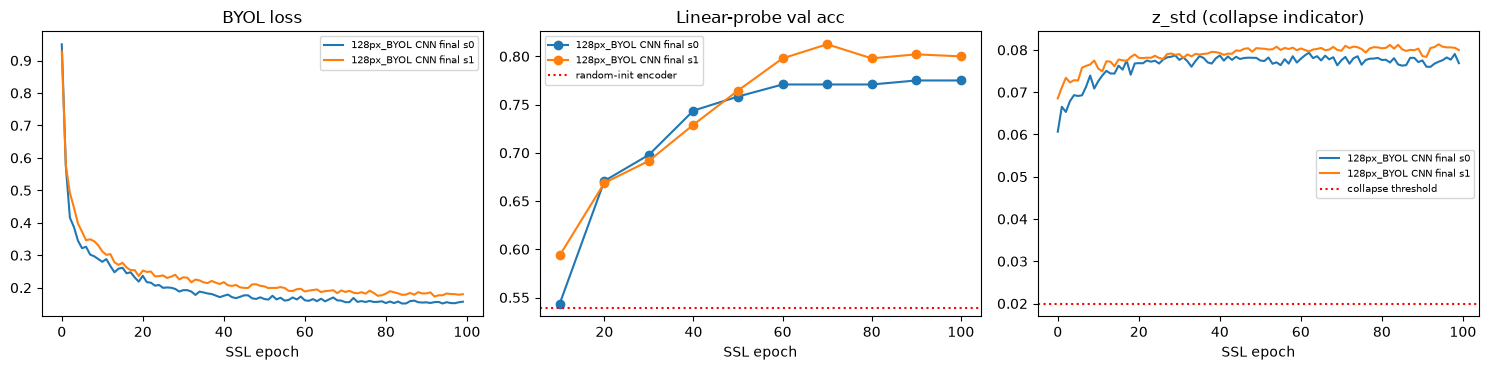

In [20]:
print(f"{'Experiment':<34}{'val best':>10}{'val last':>10}{'probe val':>11}   note")
for name, r in results.items():
    probe = f"{r['probe_val']:.4f}" if r['probe_val'] is not None else '   -'
    print(f"{name:<34}{r['val_best']:>10.4f}{r['val_last']:>10.4f}{probe:>11}   {r['note']}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name, log in probe_logs.items():
    ax[0].plot(log['loss'], label=name)
    ax[1].plot(log['probe_epoch'], log['probe_acc'], marker='o', label=name)
    ax[2].plot(log['z_std'], label=name)
ax[1].axhline(rand_probe, color='red', ls=':', label='random-init encoder')
ax[2].axhline(COLLAPSE_STD, color='red', ls=':', label='collapse threshold')
ax[0].set_title('BYOL loss'); ax[1].set_title('Linear-probe val acc'); ax[2].set_title('z_std (collapse indicator)')
for a in ax: a.set_xlabel('SSL epoch'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [21]:
# ---- Side-by-side with the SigLIP notebook's saved results (validation only; test numbers come from each notebook's own test cell) ----
def saved_summary(prefix_name, seeds):
    rows = []
    for s in seeds:
        nm = f'{PREFIX}{prefix_name} final s{s}'
        try:
            _, ck_ft = load_ckpt(nm, 'finetune')
            _, ck_pt = load_ckpt(nm, 'pretrain')
        except FileNotFoundError:
            continue
        rows.append((s, ck_pt['log']['probe_acc'][-1], max(ck_ft['history']['val_acc'])))
    return rows

print(f"{'Method':<12}{'seed':>5}{'final probe':>13}{'fine-tune val best':>20}")
for label, pn in [('SigLIP', 'SigLIP CNN'), ('BYOL', 'BYOL CNN')]:
    rows = saved_summary(pn, (0, 1, 2))
    for s, pr, vb in rows:
        print(f'{label:<12}{s:>5}{pr:>13.4f}{vb:>20.4f}')
    if rows:
        print(f"{label:<12}{'mean':>5}{np.mean([r[1] for r in rows]):>13.4f}{np.mean([r[2] for r in rows]):>20.4f}")
print('\n(Gaps under ~2-3 pts are within validation noise. SigLIP rows appear only if its notebook was run from this same project folder.)')

sg_file = CKPT_DIR / f'{PREFIX}siglip_ablation_50ep.json'
if sg_file.exists():
    sg = json.loads(sg_file.read_text())
    print(f"\n50-epoch ablation reference: SigLIP base probe {sg['base']['probe_mean2']:.4f} | BYOL base probe {abl['base']['probe_mean2']:.4f}"
          f" (both with the same shared augmentation/optimiser settings only if SigLIP kept its base config)")

Method       seed  final probe  fine-tune val best
SigLIP          0       0.7792              0.8938
SigLIP          1       0.7771              0.8896
SigLIP       mean       0.7781              0.8917
BYOL            0       0.7750              0.8958
BYOL            1       0.8000              0.8875
BYOL         mean       0.7875              0.8917

(Gaps under ~2-3 pts are within validation noise. SigLIP rows appear only if its notebook was run from this same project folder.)


C:\Users\Bryan\AppData\Local\Temp\ipykernel_23708\54230171.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ck = torch.load(CKPT_DIR / f'{slug(name)}_{stage}.pt', map_lo

## Experiment log (fill this in)

| Experiment | What changed? | Why did you try it? | Probe / val acc | Test acc | What did you learn? |
|---|---|---|---|---|---|
| BYOL base (50 ep) | Non-contrastive objective | Does SSL need negatives? | | | |
| tau 0.9 / 0.996 | EMA momentum | Target stability vs. speed | | | |
| lr x0.5 / x2 | SSL LR | | | | |
| bs half / double | Batch size | BYOL should not depend on negatives in the batch | | | |
| Combined | | | | | |
| Final (200 ep SSL + FT) | | | | | |

## Final test-set evaluation
**Run once**, after all decisions are made on validation.

In [22]:
FINALISTS = [n for n in models if n.startswith(f'{PREFIX}BYOL CNN final')]
test_accs = []
print(f"{'Model':<34}{'test loss':>11}{'test acc':>10}")
for name in FINALISTS:
    tl, ta = evaluate(models[name], test_loader, device)
    test_accs.append(ta)
    print(f'{name:<34}{tl:>11.4f}{ta:>10.4f}')
if len(test_accs) > 1:
    print(f'\nmean {np.mean(test_accs):.4f} | std {np.std(test_accs):.4f} over {len(test_accs)} seeds')

Model                               test loss  test acc
128px_BYOL CNN final s0                0.5593    0.8725
128px_BYOL CNN final s1                0.6091    0.8450

mean 0.8588 | std 0.0138 over 2 seeds


Validation (BYOL CNN, seed 0) overall accuracy: 0.8958

Class             Acc     N   Most confused with
Industrial      0.690    29   Store
Store           0.774    31   InsideCity
OpenCountry     0.786    28   Coast
InsideCity      0.800    30   Street
LivingRoom      0.808    26   Bedroom
Bedroom         0.846    39   LivingRoom
Kitchen         0.900    30   Bedroom
Highway         0.929    28   Coast
Mountain        0.929    28   Industrial
Street          0.938    32   Highway
Forest          0.966    29   Store
Flower          0.968    31   Mountain
Coast           1.000    33   -
Office          1.000    24   -
Suburb          1.000    34   -
TallBuilding    1.000    28   -


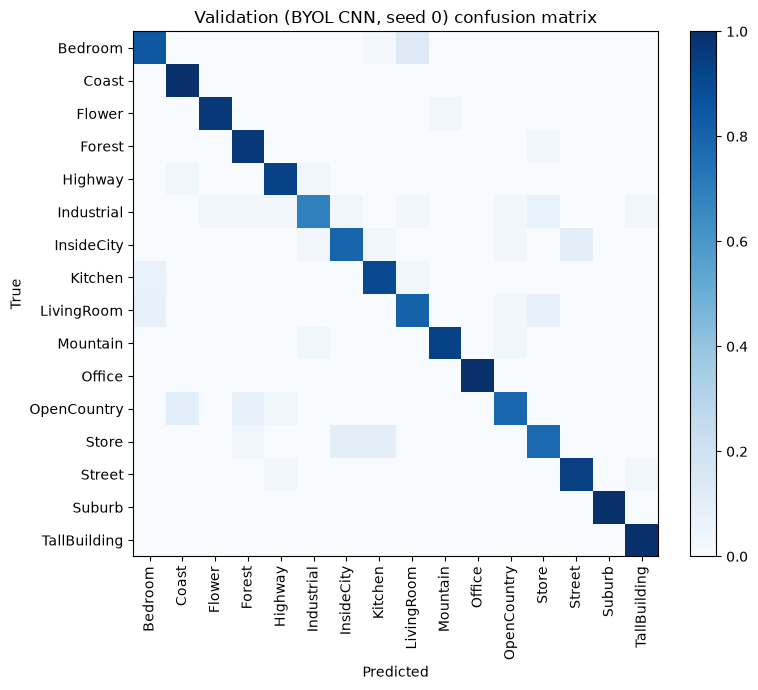

In [23]:
# Per-class analysis (from A1). Validation for decisions; switch to test_loader only for the final report.
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def per_class_report(model, loader, class_names, device, title=''):
    preds, labels = get_predictions(model, loader, device)
    n = len(class_names)
    cm = np.zeros((n, n), dtype=int)           # rows = true class, cols = predicted class
    for t, p in zip(labels, preds):
        cm[t, p] += 1
    support = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / np.maximum(support, 1)

    print(f'{title} overall accuracy: {(preds == labels).mean():.4f}\n')
    print(f'{"Class":<14}{"Acc":>7}{"N":>6}   Most confused with')
    for i in np.argsort(per_class_acc):        # worst classes first
        off = cm[i].copy(); off[i] = 0
        confused = class_names[off.argmax()] if off.sum() > 0 else '-'
        print(f'{class_names[i]:<14}{per_class_acc[i]:>7.3f}{support[i]:>6}   {confused}')

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm / np.maximum(support[:, None], 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{title} confusion matrix')
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
    return cm, per_class_acc

cm_val, acc_val = per_class_report(models[FINALISTS[0]], val_loader, class_names, device, 'Validation (BYOL CNN, seed 0)')

## Notes for the write-up
- If BYOL ≈ SigLIP within noise, the finding is that negatives are not needed at this scale; if SigLIP is clearly better, that BYOL's extra moving parts (EMA, predictor) are harder to get right on 2,400 images — but say how few BYOL settings were tried vs. SigLIP.
- Report `z_std` / the random-init probe floor if any run collapsed; that is a result, not a bug, as long as the other runs are healthy.